# Module 1: Paths and One-Dimensional Lattices

In [4]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

## Question 1
Compute the diameter $d_{\max} = \max_{i,j} d_{ij}$ of the network in Figure 1.

**Solution.** The network is a chain: node $i$ is only linked to $i-1$ and $i+1$, 
and there are no cycles. So there is exactly one path between any two nodes, and

$$d_{ij} = |i - j|.$$

The distance is largest between the two end nodes:

$$d_{\max} = d_{1,9} = 8.$$

In [5]:
# Build the network from Figure 1: nodes 1..9, links (1,2), (2,3), ..., (8,9)
G = nx.path_graph(range(1, 10))
print(G.edges())

# Diameter computed by networkx
print("Diameter:", nx.diameter(G))

[(1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 8), (8, 9)]
Diameter: 8


## Question 2
Distance $d_{ij}$ between any two nodes of a chain of length $n-1$.

**Solution.**

A chain of length $n-1$ has $n-1$ edges and therefore $n$ nodes, $V = \{1, \dots, n\}$, 
with edges $(i, i+1)$ for $i = 1, \dots, n-1$.

Take two nodes $i < j$ (the case $i > j$ is symmetric).

*Step 1 (upper bound).* Walking along the chain, $i \to i+1 \to \dots \to j$, 
is a path with $j - i$ edges, so

$$d_{ij} \leq j - i.$$

*Step 2 (lower bound).* Every edge $(m, m+1)$ with $i \leq m < j$ separates $i$ from $j$: 
removing it splits the chain into two parts, with $i$ on one side and $j$ on the other. 
So every path from $i$ to $j$ must use all $j - i$ of these edges, and

$$d_{ij} \geq j - i.$$

*Step 3.* Together, $d_{ij} = j - i$ for $i < j$. By symmetry $d_{ij} = i - j$ for $i > j$, 
and $d_{ii} = 0$. In one formula:

$$d_{ij} = |i - j| \qquad \forall\, i, j \in \{1, \dots, n\}.$$

*Check:* for Figure 1 ($n = 9$), $d_{1,9} = 8$, the diameter from Question 1.

In [6]:
for n in range(2, 12):                       # chains with 2 to 11 nodes
    C = nx.path_graph(range(1, n + 1))       # chain of length n-1: nodes 1..n
    dist = dict(nx.all_pairs_shortest_path_length(C))
    for i in C:
        for j in C:
            assert dist[i][j] == abs(i - j)

print("d_ij = |i - j| holds for all tested chains")

d_ij = |i - j| holds for all tested chains


## Question 3
Average distance $\langle d \rangle$ of a chain of length $n-1$ ($n$ nodes).

**Solution.**

Using $d_{ij} = |i-j|$ from Question 2:

$$\langle d \rangle = \frac{1}{n(n-1)} \sum_{i=1}^{n}\sum_{j=1}^{n} |i-j| = \frac{S}{n(n-1)}.$$

*Step 1 (symmetry).* The diagonal ($i=j$) contributes 0, and $|i-j| = |j-i|$, so

$$S = 2 \sum_{i<j} (j-i).$$

*Step 2 (group by distance).* There are $n-m$ pairs at distance $m = j-i$, 
for $m = 1, \dots, n-1$. Hence

$$\sum_{i<j} (j-i) = \sum_{m=1}^{n-1} m(n-m) = n\sum_{m=1}^{n-1} m - \sum_{m=1}^{n-1} m^2.$$

*Step 3 (standard sums).* With $\sum_{m=1}^{N} m = \frac{N(N+1)}{2}$ and 
$\sum_{m=1}^{N} m^2 = \frac{N(N+1)(2N+1)}{6}$ for $N = n-1$:

$$\sum_{m=1}^{n-1} m(n-m) = n\cdot\frac{(n-1)n}{2} - \frac{(n-1)n(2n-1)}{6} 
= n(n-1)\cdot\frac{3n-(2n-1)}{6} = \frac{n(n-1)(n+1)}{6}.$$

*Step 4.* So $S = \frac{n(n-1)(n+1)}{3}$ and

$$\langle d \rangle_{\text{chain}} = \frac{n+1}{3}.$$

*Check:* $n = 4$ gives $\frac{20}{12} = \frac{5}{3}$ by adding up all distances directly. 
The average distance grows linearly in $n$.

In [8]:
for n in range(2, 30):
    C = nx.path_graph(n)
    assert np.isclose(nx.average_shortest_path_length(C), (n + 1) / 3)

print("<d> = (n+1)/3 holds for all tested chains")

<d> = (n+1)/3 holds for all tested chains


## Question 4
Average distance of the ring with $n = 12$ nodes (Figure 3).

**Solution.**

In a ring, the distance is the shorter of the two ways around:

$$d_{ij} = \min\big(|i-j|,\; n - |i-j|\big).$$

Distances from node 1 to nodes $2, \dots, 12$: $1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1$, with sum

$$\sum_j d_{1j} = 2(1+2+3+4+5) + 6 = 36.$$

The ring is symmetric: every node sees the same distances, so every row of the 
distance matrix sums to 36. Therefore

$$\langle d \rangle = \frac{1}{12 \cdot 11} \cdot 12 \cdot 36 = \frac{36}{11} \approx 3.27.$$

In [9]:
R = nx.cycle_graph(12)        # ring with 12 nodes
print(nx.average_shortest_path_length(R))
print(36 / 11)

3.272727272727273
3.272727272727273


## Question 5
Average distance of a ring of size $n$, for odd $n$.

**Solution.**

*Symmetry.* Writing

$$\langle d \rangle = \frac{1}{n}\sum_i \left(\frac{1}{n-1}\sum_j d_{ij}\right) = \frac{1}{n}\sum_i L_i,$$

we see that $\langle d \rangle$ is the average of the $L_i$. In a ring every node sees 
the same distances, so all $L_i$ are equal and $\langle d \rangle = L_i$.

*Distances from one node.* For odd $n$, let $M = \frac{n-1}{2}$. Going around the ring 
in both directions, each distance $1, 2, \dots, M$ appears exactly twice 
($2M = n-1$ nodes in total). Hence

$$\sum_j d_{ij} = 2\sum_{m=1}^{M} m = M(M+1),
\qquad
L_i = \frac{M(M+1)}{2M} = \frac{M+1}{2} = \frac{n+1}{4}.$$

*Result.*

$$\langle d \rangle_{\text{ring}} = \frac{n+1}{4} \quad (n \text{ odd}).$$

*Check:* $n = 7$ gives distances $1,2,3,3,2,1$, so $L = 12/6 = 2 = 8/4$.

In [10]:
for n in range(3, 40, 2):                  # odd n only: 3, 5, 7, ..., 39
    R = nx.cycle_graph(n)
    assert np.isclose(nx.average_shortest_path_length(R), (n + 1) / 4)

print("<d> = (n+1)/4 holds for all tested odd rings")

<d> = (n+1)/4 holds for all tested odd rings


## Question 6
Average distance of a 1D periodic lattice with coordination number $k$, 
for odd $n$ with $\frac{n-1}{2k}$ an integer.

**Solution.**

By symmetry (as in Question 5), every node sees the same distances, so 
$\langle d \rangle = L_i$.

*Distances from one node.* On each side of node $i$ there are $\frac{n-1}{2}$ nodes 
($n$ odd). One step covers at most $k$ positions, so the nodes at offsets 
$1,\dots,k$ are at distance 1, offsets $k+1,\dots,2k$ at distance 2, and so on. 
Since $\frac{n-1}{2k}$ is an integer, each side splits into exactly

$$D = \frac{n-1}{2k}$$

complete blocks. So every distance $m = 1, \dots, D$ appears exactly $k$ times per 
side, i.e. $2k$ times in total.

*Sum and average.*

$$\sum_j d_{ij} = 2k\sum_{m=1}^{D} m = k\,D(D+1),
\qquad
L_i = \frac{k\,D(D+1)}{n-1} = \frac{k\,D(D+1)}{2kD} = \frac{D+1}{2}.$$

*Result.*

$$\langle d \rangle = \frac{n-1}{4k} + \frac{1}{2}.$$

*Checks:* $n=13, k=2$ gives distances $1,1,2,2,3,3$ on each side, so $L = 24/12 = 2$. 
For $k = 1$ the formula reduces to the ring result $\frac{n+1}{4}$.

In [ ]:
for k in range(1, 5):
    for D in range(1, 11):
        n = 2 * k * D + 1                      # odd n, and (n-1)/(2k) = D is an integer
        L = nx.circulant_graph(n, range(1, k + 1))
        assert np.isclose(nx.average_shortest_path_length(L),
                          (n - 1) / (4 * k) + 1 / 2)

print("Formula holds for all tested lattices")

## Summary

*Small-network checks.* All formulas agree with hand calculations 
(chain $n=4$: $5/3$; ring $n=7$: $2$; lattice $n=13, k=2$: $2$) and with 
`networkx` for many sizes.

*Scaling.* For large $n$:

| Network | $\langle d \rangle$ | large $n$ |
|---|---|---|
| Chain | $\frac{n+1}{3}$ | $\approx n/3$ |
| Ring | $\frac{n+1}{4}$ | $\approx n/4$ |
| Periodic lattice | $\frac{n-1}{4k} + \frac{1}{2}$ | $\approx n/(4k)$ |

All three grow **linearly** in $n$. Periodic boundaries reduce $\langle d \rangle$ by a 
factor $3/4$, and a larger coordination number by a factor $1/k$, but neither changes 
the linear scaling: one step moves at most $k$ positions, so crossing the network 
takes a number of steps proportional to $n$.

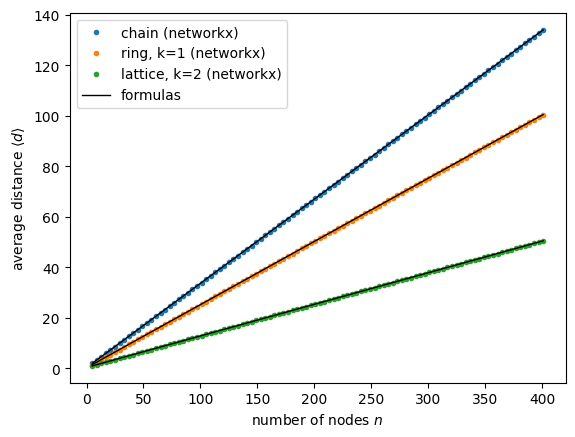

In [11]:
ns = np.arange(5, 402, 4)      # odd n with (n-1) divisible by 4: valid for k = 1 and k = 2

chain = [nx.average_shortest_path_length(nx.path_graph(n)) for n in ns]
ring  = [nx.average_shortest_path_length(nx.cycle_graph(n)) for n in ns]
latt2 = [nx.average_shortest_path_length(nx.circulant_graph(n, [1, 2])) for n in ns]

plt.plot(ns, chain, "o", ms=3, label="chain (networkx)")
plt.plot(ns, ring,  "o", ms=3, label="ring, k=1 (networkx)")
plt.plot(ns, latt2, "o", ms=3, label="lattice, k=2 (networkx)")

plt.plot(ns, (ns + 1) / 3, "k-",  lw=1, label="formulas")
plt.plot(ns, (ns + 1) / 4, "k-",  lw=1)
plt.plot(ns, (ns - 1) / 8 + 0.5, "k-", lw=1)

plt.xlabel("number of nodes $n$")
plt.ylabel(r"average distance $\langle d \rangle$")
plt.legend()
plt.show()